# Nonlinear optimization

## Optimum power for a set of $m$ lamps illuminating a set of $n$ flat patches to best approach a target illumination

Consider $m$ lamps illuminating $n$ (small flat) patches. The illumination intensity $I_k$ at the $k$-th patch depends linearly on the lamp powers $p_j$ as:
$$
I_k = \sum\limits_{j=1}^m a_{k,j}p_j, \quad \text{with} \quad a_{k,j} = r^{-2}_{k,j}\max\{\cos(\theta_{k,j}, 0\},
$$
where $r_{k,j}$ is the length of the vector $\mathbf{r}_{k,j}$ connecting the center of the $k$-th patch to the position of the $m$-th lamp and $\theta_{k,j}$ is the angle between the patch normal vector $\mathbf{n}_{k}$ and $\mathbf{r}_{k,j}$. See the Convex Optimization book slides for more details.

The proposed problem is to achieve a desired illumination $I_{des}$ with bounded lamp powers ($p_{max}$), i.e.,
$$
\begin{align*}
    & \min. \underset{k=1, 2, \ldots, n}{\max}\vert \log(I_k) - \log(I_{des})\vert \\
    \text{s. t.}\quad & 0 \leq p_j \leq p_{max}, j = 1, 2, \ldots, m.
\end{align*}
$$


### Suboptimally solve the problem using according to the following approaches:

1. Using uniform power, i.e., $p_j = p, 0 \leq p \leq p_{max}$.
2. Using least-squares, i.e., $ \min. \sum\limits_{k=1}^n (I_k - I_{des})^2$, and rounding $p_j$ as $p_j = \max\{0, \min\{p_j, p_{max}\}\}$.
3. Using weighted least-squares, i.e., $ \min. \sum\limits_{k=1}^n (I_k - I_{des})^2 + \sum\limits_{j=1}^m w_j (p_j - p_{max}/2)^2$ and iteratively adjusting the weights $w_j$ until $0 \leq p \leq p_{max}, \forall j$.
4. Using linear programming, i.e.,
$$
\begin{align*}
    & \min. \underset{k=1, 2, \ldots, n}{\max}\vert I_k - I_{des}\vert \\
    \text{s. t.}\quad & 0 \leq p_j \leq p_{max}, j = 1, 2, \ldots, m.
\end{align*}
$$

### Solve the problem optimally using convex optimization

For this goal, consider the equivalent convex problem
$$
\begin{align*}
    & \min. \underset{k=1, 2, \ldots, n}{\max}h(I_k/I_{des}) \\
    \text{s. t.}\quad & 0 \leq p_j \leq p_{max}, j = 1, 2, \ldots, m,
\end{align*}
$$
where $h(u) = \max\{u, 1/u\}$.


# Scenario generation

We begin the problem by creating the scenario with a certain number of patches (numPatches) and a certain amount of lamps (numLamps).

In [4]:
def generate_scenario(numLamps : int, numPatches : int):
    # Preallocate the patch and lamp positions
    patchPos = np.zeros((numPatches+1, 2), dtype=float)
    lampPos = np.zeros((numLamps, 2), dtype=float)

    # Generate patches extreme points
    x_patches = 1 + 3 * np.random.rand(numPatches+1)
    x_patches = np.cumsum(x_patches)
    y_patches = 2 + 1 * np.random.rand(numPatches+1)
    patchPos[:, 0] = x_patches
    patchPos[:, 1] = y_patches

    # Generate lamp extreme points
    # x_lamps = 1 + 5 * np.random.rand(numLamps)
    # x_lamps = np.cumsum(x_lamps)
    x_lamps = min(x_patches) + (max(x_patches) - min(x_patches)) * np.random.rand(numLamps)
    y_lamps = 6 + 1 * np.random.rand(numLamps)
    lampPos[:, 0] = x_lamps
    lampPos[:, 1] = y_lamps

    # return
    return patchPos, lampPos

Now we set the simulation parameters and create a representation of the scenario

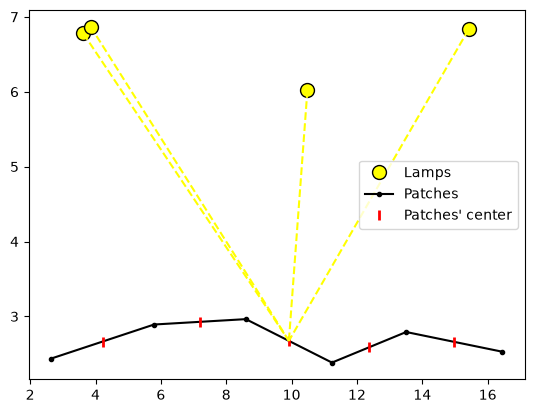

In [35]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp

# Seed
np.random.seed(0)

'''Simulation parameters'''
showFig = True;          # Figure
numLamps = 4;           # Number of lamps 4
numPatches = 5;         # Number of patches 5
maxPwr = 1;              # Maximum power [W]
desiredillum = 0.01;     # Desired illumination

# Position of the lamps and the extreme points of the patches in real matrices
# We assume that the lamps will be higher than the patches
# lampPos = np.array([[0.6838, 7.8976], [3.1835, 7.0690], [5.5327, 6.6806], [6.1963, 6.5203]])
# patchPos = np.array([[0.0762, 2.8621], [1.4506, 2.8733], [2.5122, 2.5864], [4.2246, 3.5846], [5.3512, 2.1960], [6.3013, 2.9838]])
patchPos, lampPos = generate_scenario(numLamps, numPatches)

# Position of the lamps and the extreme points of the patches in complex vectors
lampPos = lampPos[:, 0] + 1j * lampPos[:, 1]
patchPos = patchPos[:, 0] + 1j * patchPos[:, 1]

# Get the center of each patch
patchCenter = (patchPos[0:-1] + patchPos[1:]) / 2

# Obtain the normal versors to the patches
patch_diff_vector = patchPos[1:]-patchPos[0:-1]
normal_vectors = -np.imag(patch_diff_vector) + 1j * np.real(patch_diff_vector)
normal_versors = normal_vectors / np.abs(normal_vectors)    # Note that each vector is represented by a complex number

# Obtain the distance "vectors" represented by a complex number
mt_coeff = np.zeros((len(patchCenter), len(lampPos)), float)
for c1 in range(len(patchCenter)):
    for c2 in range(len(lampPos)):
        dist_vector = lampPos[c2] - patchCenter[c1]
        # We assume lamps in higher positions than patches
        ang = np.real(dist_vector * np.conjugate(normal_versors[c1])) / np.abs(dist_vector)
        mt_coeff[c1, c2] = (np.abs(dist_vector)**(-2)) * max(ang, 0)

''' Plot of the scenario '''
if showFig:
    # Plot the lamps
    plt.plot(np.real(lampPos), np.imag(lampPos), 'o', color="yellow", markersize = 10, markeredgecolor = 'k', label = "Lamps")

    # Plot the patches
    plt.plot(np.real(patchPos), np.imag(patchPos), 'o-', color = 'k', markersize = 3, label = "Patches")

    # Plot the center of the patches
    plt.plot(np.real(patchCenter), np.imag(patchCenter), '|', color = 'r', markersize = 7, markeredgewidth=2, label = "Patches' center")

    # Plot the lamps rays to a certain patch
    for c1 in range(len(lampPos)):
        plt.plot([np.real(lampPos[c1]), np.real(patchCenter[2])], [np.imag(lampPos[c1]), np.imag(patchCenter[2])], '--', color = "yellow")

    plt.legend()
    plt.show